In [42]:
import pandas as pd
import numpy as np  


In [43]:
df=pd.read_csv('D:\\DATA science projects\\RossmanStoreSales\\datasets\\train.csv', low_memory=False)

In [44]:
df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [46]:
df1=pd.read_csv(r'D:\DATA science projects\RossmanStoreSales\datasets\store.csv')
df1.head()

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [45]:
pd.merge(df,df1,how='left',on='Store').groupby('StoreType')['Store'].value_counts()

StoreType  Store
a          558      942
           855      942
           439      942
           853      942
           848      942
                   ... 
d          430      758
           851      758
           457      758
           842      758
           471      758
Name: count, Length: 1115, dtype: int64

In [47]:
pd.merge(df, df1, how='left', on='Store').groupby('StoreType')['Store'].nunique()


StoreType
a    602
b     17
c    148
d    348
Name: Store, dtype: int64

In [48]:
pd.merge(df, df1, how='left', on='Store').groupby('StoreType')['Store'].count()


StoreType
a    551627
b     15830
c    136840
d    312912
Name: Store, dtype: int64

In [49]:
df['Date']=pd.to_datetime(df['Date'],errors='coerce')

In [50]:
df['Date'].isna().sum()

np.int64(0)

In [51]:
df.duplicated().sum()

np.int64(0)

<Axes: xlabel='Sales'>

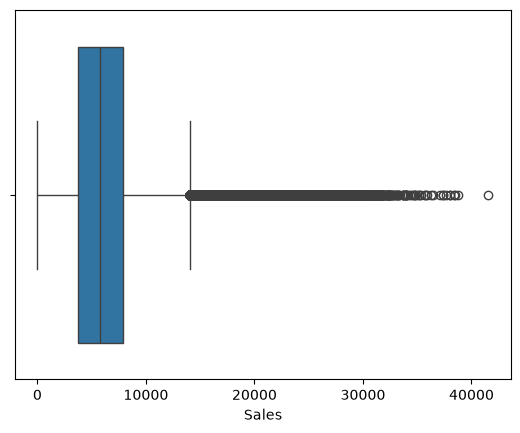

In [52]:
import seaborn as sns
sns.boxplot(x=df['Sales'])


<Axes: xlabel='Customers'>

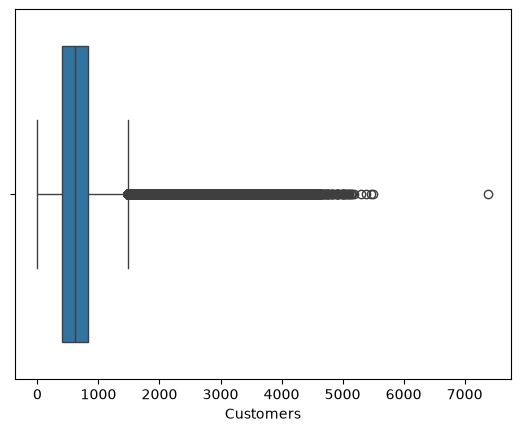

In [53]:
import seaborn as sns
sns.boxplot(x=df['Customers'])


In [54]:
import seaborn as sns
df.corr(numeric_only=True)

,Store,DayOfWeek,Sales,Customers,Open,Promo,SchoolHoliday
Store,1.000000,-0.000008,0.005126,0.024325,-0.000047,0.000058,0.000641
DayOfWeek,-0.000008,1.000000,-0.462125,-0.386445,-0.528963,-0.392925,-0.205388
Sales,0.005126,-0.462125,1.000000,0.894711,0.678472,0.452345,0.085124
Customers,0.024325,-0.386445,0.894711,1.000000,0.616768,0.316169,0.071568
Open,-0.000047,-0.528963,0.678472,0.616768,1.000000,0.295042,0.086171
Promo,0.000058,-0.392925,0.452345,0.316169,0.295042,1.000000,0.067483
SchoolHoliday,0.000641,-0.205388,0.085124,0.071568,0.086171,0.067483,1.000000


In [55]:
df.corr(method='spearman',numeric_only=True)


,Store,DayOfWeek,Sales,Customers,Open,Promo,SchoolHoliday
Store,1.000000,-0.000008,0.000545,0.021653,-0.000047,0.000058,0.000640
DayOfWeek,-0.000008,1.000000,-0.450717,-0.430877,-0.528344,-0.392785,-0.205313
Sales,0.000545,-0.450717,1.000000,0.903353,0.652013,0.489565,0.083384
Customers,0.021653,-0.430877,0.903353,1.000000,0.652015,0.377257,0.079207
Open,-0.000047,-0.528344,0.652013,0.652015,1.000000,0.295042,0.086171
Promo,0.000058,-0.392785,0.489565,0.377257,0.295042,1.000000,0.067483
SchoolHoliday,0.000640,-0.205313,0.083384,0.079207,0.086171,0.067483,1.000000


In [56]:
pd.merge(df,df1,on='Store',how='left').corr(numeric_only=True)

,Store,DayOfWeek,Sales,Customers,Open,Promo,SchoolHoliday,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear
Store,1.000000,-0.000008,0.005126,0.024325,-0.000047,0.000058,0.000641,-0.026413,-0.050746,-0.004592,0.008488,0.009865,0.038928
DayOfWeek,-0.000008,1.000000,-0.462125,-0.386445,-0.528963,-0.392925,-0.205388,-0.000025,0.000006,-0.000025,0.000168,0.000174,0.000049
Sales,0.005126,-0.462125,1.000000,0.894711,0.678472,0.452345,0.085124,-0.019229,-0.028257,0.012659,-0.091040,0.059558,-0.021127
Customers,0.024325,-0.386445,0.894711,1.000000,0.616768,0.316169,0.071568,-0.102861,-0.030954,0.008931,-0.150159,0.040531,0.028974
Open,-0.000047,-0.528963,0.678472,0.616768,1.000000,0.295042,0.086171,0.007992,0.001384,0.002771,-0.008309,-0.002430,0.001637
Promo,0.000058,-0.392925,0.452345,0.316169,0.295042,1.000000,0.067483,0.000138,-0.000023,0.000152,-0.000983,-0.001008,-0.000283
SchoolHoliday,0.000641,-0.205388,0.085124,0.071568,0.086171,0.067483,1.000000,-0.003689,-0.000526,0.001520,-0.006909,-0.003133,-0.003682
CompetitionDistance,-0.026413,-0.000025,-0.019229,-0.102861,0.007992,0.000138,-0.003689,1.000000,-0.061624,0.025397,-0.139886,-0.054384,-0.109695
CompetitionOpenSinceMonth,-0.050746,0.000006,-0.028257,-0.030954,0.001384,-0.000023,-0.000526,-0.061624,1.000000,-0.060594,-0.009383,-0.036251,0.050326
CompetitionOpenSinceYear,-0.004592,-0.000025,0.012659,0.008931,0.002771,0.000152,0.001520,0.025397,-0.060594,1.000000,-0.077336,-0.079784,0.012155


In [57]:
pd.merge(df,df1,on='Store',how='left').corr(numeric_only=True,method='spearman')

,Store,DayOfWeek,Sales,Customers,Open,Promo,SchoolHoliday,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear
Store,1.000000,-0.000008,0.000545,0.021653,-0.000047,5.786949e-05,0.000640,-4.568264e-02,-0.051750,0.004061,0.008556,0.005512,0.035383
DayOfWeek,-0.000008,1.000000,-0.450717,-0.430877,-0.528344,-3.927855e-01,-0.205313,-1.795446e-06,0.000006,-0.000006,0.000168,0.000182,0.000054
Sales,0.000545,-0.450717,1.000000,0.903353,0.652013,4.895654e-01,0.083384,-2.423468e-02,-0.028126,0.039706,-0.085974,0.064550,-0.022347
Customers,0.021653,-0.430877,0.903353,1.000000,0.652015,3.772571e-01,0.079207,-1.772956e-01,-0.021034,0.039461,-0.163128,0.024390,0.031799
Open,-0.000047,-0.528344,0.652013,0.652015,1.000000,2.950423e-01,0.086171,1.309612e-04,0.001172,0.003079,-0.008309,-0.002867,0.001543
Promo,0.000058,-0.392785,0.489565,0.377257,0.295042,1.000000e+00,0.067483,-7.807418e-07,-0.000022,0.000040,-0.000983,-0.001057,-0.000311
SchoolHoliday,0.000640,-0.205313,0.083384,0.079207,0.086171,6.748281e-02,1.000000,-3.144196e-03,-0.000636,0.000796,-0.006909,-0.003552,-0.003555
CompetitionDistance,-0.045683,-0.000002,-0.024235,-0.177296,0.000131,-7.807418e-07,-0.003144,1.000000e+00,-0.034665,-0.003883,-0.091524,-0.020451,-0.087802
CompetitionOpenSinceMonth,-0.051750,0.000006,-0.028126,-0.021034,0.001172,-2.249360e-05,-0.000636,-3.466475e-02,1.000000,-0.124549,-0.006001,-0.038545,0.046144
CompetitionOpenSinceYear,0.004061,-0.000006,0.039706,0.039461,0.003079,4.026208e-05,0.000796,-3.882763e-03,-0.124549,1.000000,-0.058217,-0.000243,0.101682


In [59]:
mergeddf=pd.merge(df,df1,on='Store',how='left')

<Axes: xlabel='Customers', ylabel='CompetitionDistance'>

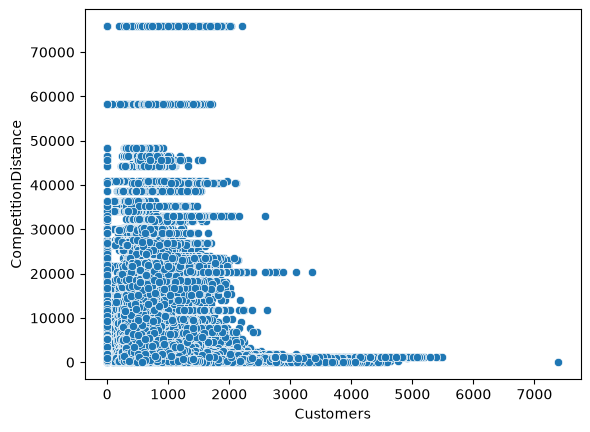

In [60]:
sns.scatterplot(x=mergeddf['Customers'], y=mergeddf['CompetitionDistance'])

In [61]:
import pandas as pd
from sklearn.feature_selection import mutual_info_regression

# 1. NaN values hatayein (sirf in dono columns ke liye)
temp_df = mergeddf[['Customers', 'CompetitionDistance']].dropna()

# 2. Double brackets [[]] se X ko 2D DataFrame banayein
X = temp_df[['Customers']]
y = temp_df['CompetitionDistance']

# 3. MI score nikalein
mi_scores = mutual_info_regression(X, y, random_state=42)

# 4. Result print karein
mi_series = pd.Series(mi_scores, index=X.columns)
print(mi_series)


Customers    0.390607
dtype: float64


In [62]:
import pandas as pd
from sklearn.feature_selection import mutual_info_regression

# 1. NaN values hatayein (sirf in dono columns ke liye)
temp_df = mergeddf[['Sales', 'CompetitionOpenSinceMonth']].dropna()

# 2. Double brackets [[]] se X ko 2D DataFrame banayein
X = temp_df[['Sales']]
y = temp_df['CompetitionOpenSinceMonth']

# 3. MI score nikalein
mi_scores = mutual_info_regression(X, y, random_state=42)

# 4. Result print karein
mi_series = pd.Series(mi_scores, index=X.columns)
print(mi_series)

Sales    0.014201
dtype: float64


In [63]:
import pandas as pd
from sklearn.feature_selection import mutual_info_regression

# 1. NaN values hatayein (sirf in dono columns ke liye)
temp_df = mergeddf[['Sales', 'CompetitionOpenSinceYear']].dropna()

# 2. Double brackets [[]] se X ko 2D DataFrame banayein
X = temp_df[['Sales']]
y = temp_df['CompetitionOpenSinceYear']

# 3. MI score nikalein
mi_scores = mutual_info_regression(X, y, random_state=42)

# 4. Result print karein
mi_series = pd.Series(mi_scores, index=X.columns)
print(mi_series)

Sales    0.023674
dtype: float64


In [64]:
import pandas as pd
from sklearn.feature_selection import mutual_info_regression

# 1. NaN values hatayein (sirf in dono columns ke liye)
temp_df = mergeddf[['Customers','CompetitionOpenSinceYear']].dropna()

# 2. Double brackets [[]] se X ko 2D DataFrame banayein
X = temp_df[['Customers']]
y = temp_df['CompetitionOpenSinceYear']

# 3. MI score nikalein
mi_scores = mutual_info_regression(X, y, random_state=42)

# 4. Result print karein
mi_series = pd.Series(mi_scores, index=X.columns)
print(mi_series)

Customers    0.034535
dtype: float64


In [65]:
import pandas as pd
from sklearn.feature_selection import mutual_info_regression

# 1. NaN values hatayein (sirf in dono columns ke liye)
temp_df = mergeddf[['Customers', 'CompetitionOpenSinceYear']].dropna()

# 2. Double brackets [[]] se X ko 2D DataFrame banayein
X = temp_df[['Customers']]
y = temp_df['CompetitionOpenSinceYear']

# 3. MI score nikalein
mi_scores = mutual_info_regression(X, y, random_state=42)

# 4. Result print karein
mi_series = pd.Series(mi_scores, index=X.columns)
print(mi_series)

Customers    0.034535
dtype: float64


In [66]:
mergeddf.isna().sum()

Store                             0
DayOfWeek                         0
Date                              0
Sales                             0
Customers                         0
Open                              0
Promo                             0
StateHoliday                      0
SchoolHoliday                     0
StoreType                         0
Assortment                        0
CompetitionDistance            2642
CompetitionOpenSinceMonth    323348
CompetitionOpenSinceYear     323348
Promo2                            0
Promo2SinceWeek              508031
Promo2SinceYear              508031
PromoInterval                508031
dtype: int64

In [67]:
mergeddf[mergeddf['CompetitionOpenSinceMonth'].isna() & mergeddf['CompetitionOpenSinceYear'].isna()][mergeddf['CompetitionDistance'].isna()==False].value_counts()


C:\Users\om\AppData\Local\Temp\ipykernel_8804\1360701360.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  mergeddf[mergeddf['CompetitionOpenSinceMonth'].isna() & mergeddf['CompetitionOpenSinceYear'].isna()][mergeddf['CompetitionDistance'].isna()==False].value_counts()


Series([], Name: count, dtype: int64)

In [68]:
len(mergeddf[
    mergeddf['CompetitionOpenSinceMonth'].isna() & 
    mergeddf['CompetitionOpenSinceYear'].isna() & 
    mergeddf['CompetitionDistance'].notna()
])

320706

In [69]:
320706+2642

323348

In [70]:
mergeddf[
    mergeddf['CompetitionOpenSinceMonth'].isna() & 
    mergeddf['CompetitionOpenSinceYear'].isna() & 
    mergeddf['CompetitionDistance'].notna()
]

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
11,12,5,2015-07-31,8959,962,1,1,0,1,a,c,1070.0,NaN,NaN,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
12,13,5,2015-07-31,8821,568,1,1,0,0,d,a,310.0,NaN,NaN,1,45.0,2009.0,"Feb,May,Aug,Nov"
15,16,5,2015-07-31,10231,979,1,1,0,1,a,c,3270.0,NaN,NaN,0,NaN,NaN,NaN
18,19,5,2015-07-31,8234,718,1,1,0,1,a,c,3240.0,NaN,NaN,1,22.0,2011.0,"Mar,Jun,Sept,Dec"
21,22,5,2015-07-31,6566,633,1,1,0,0,a,a,1040.0,NaN,NaN,1,22.0,2012.0,"Jan,Apr,Jul,Oct"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1017189,1096,2,2013-01-01,0,0,0,0,a,1,a,c,1130.0,NaN,NaN,1,10.0,2014.0,"Mar,Jun,Sept,Dec"
1017193,1100,2,2013-01-01,0,0,0,0,a,1,a,a,540.0,NaN,NaN,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
1017206,1113,2,2013-01-01,0,0,0,0,a,1,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN
1017207,1114,2,2013-01-01,0,0,0,0,a,1,a,c,870.0,NaN,NaN,0,NaN,NaN,NaN


In [71]:
mergeddf[(mergeddf['CompetitionOpenSinceYear'].isna()) & (mergeddf['CompetitionOpenSinceMonth'].notnull())]

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval


In [72]:
# Maan lijiye aapke paas Date column datetime format mein hai
mergeddf['Date'] = pd.to_datetime(mergeddf['Date'])
mergeddf['Year'] = mergeddf['Date'].dt.year
mergeddf['Month'] = mergeddf['Date'].dt.month

# 1. Naya feature banayein (jahan Year/Month NaN hai, wahan ye bhi NaN banega)
mergeddf['CompetitionOpenMonths'] = (
    (mergeddf['Year'] - mergeddf['CompetitionOpenSinceYear']) * 12 + 
    (mergeddf['Month'] - mergeddf['CompetitionOpenSinceMonth'])
)

# 2. Agar koi competition future date ka dikha raha hai (negative value), toh usko 0 kar dein
mergeddf['CompetitionOpenMonths'] = mergeddf['CompetitionOpenMonths'].clip(lower=0)

# 3. Ab saare NaNs ko seedha 0 se fill kar dein
mergeddf['CompetitionOpenMonths'].fillna(0, inplace=True)

# 4. Purane dono columns drop kar dein
mergeddf.drop(columns=['CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear'], inplace=True)


C:\Users\om\AppData\Local\Temp\ipykernel_8804\1093208619.py:16: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  mergeddf['CompetitionOpenMonths'].fillna(0, inplace=True)
C:\Users\om\AppData\Local\Temp\ipykernel_8804\1093208619.py:19: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future

In [73]:
mergeddf.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Year,Month,CompetitionOpenMonths
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,0,NaN,NaN,NaN,2015,7,82.0
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct",2015,7,92.0
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",2015,7,103.0
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,0,NaN,NaN,NaN,2015,7,70.0
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,0,NaN,NaN,NaN,2015,7,3.0


In [74]:
# Promo2 se jude saare columns ek saath drop karein (errors='ignore' se agar koi column pehle se nahi hai toh error nahi aayega)
promo2_cols = ['Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']
mergeddf.drop(columns=promo2_cols, inplace=True, errors='ignore')


C:\Users\om\AppData\Local\Temp\ipykernel_8804\841162089.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  mergeddf.drop(columns=promo2_cols, inplace=True, errors='ignore')


In [75]:
mergeddf.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,Year,Month,CompetitionOpenMonths
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,2015,7,82.0
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,2015,7,92.0
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,2015,7,103.0
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,2015,7,70.0
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,2015,7,3.0


In [76]:
mergeddf.drop(columns=[
    'Date', 
    'Year'
], inplace=True, errors='ignore')


C:\Users\om\AppData\Local\Temp\ipykernel_8804\4128327414.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  mergeddf.drop(columns=[


In [77]:
mergeddf.drop(columns=[
    'Month'
], inplace=True, errors='ignore')


C:\Users\om\AppData\Local\Temp\ipykernel_8804\2621993102.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  mergeddf.drop(columns=[


In [78]:
mergeddf.isna().sum()

Store                         0
DayOfWeek                     0
Sales                         0
Customers                     0
Open                          0
Promo                         0
StateHoliday                  0
SchoolHoliday                 0
StoreType                     0
Assortment                    0
CompetitionDistance        2642
CompetitionOpenMonths    323348
dtype: int64

In [79]:
mergeddf.head()

,Store,DayOfWeek,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenMonths
0,1,5,5263,555,1,1,0,1,c,a,1270.0,82.0
1,2,5,6064,625,1,1,0,1,a,a,570.0,92.0
2,3,5,8314,821,1,1,0,1,a,a,14130.0,103.0
3,4,5,13995,1498,1,1,0,1,c,c,620.0,70.0
4,5,5,4822,559,1,1,0,1,a,a,29910.0,3.0


In [80]:
mergeddf.head()

,Store,DayOfWeek,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenMonths
0,1,5,5263,555,1,1,0,1,c,a,1270.0,82.0
1,2,5,6064,625,1,1,0,1,a,a,570.0,92.0
2,3,5,8314,821,1,1,0,1,a,a,14130.0,103.0
3,4,5,13995,1498,1,1,0,1,c,c,620.0,70.0
4,5,5,4822,559,1,1,0,1,a,a,29910.0,3.0


In [40]:
CompetitionDistance        2642
Month                         0
CompetitionOpenMonths    323348

SyntaxError: invalid syntax (4165091184.py, line 1)

In [81]:
# Har StoreType ke liye total rows aur missing counts check karein
missing_by_storetype = mergeddf.groupby('StoreType').agg(
    Total_Rows=('Store', 'count'),
    Dist_Missing=('CompetitionDistance', lambda x: x.isna().sum()),
    OpenMonths_Missing=('CompetitionOpenMonths', lambda x: x.isna().sum())
)

# Percentage bhi dekh lein taaki comparison aasaan ho
missing_by_storetype['OpenMonths_Missing_%'] = (
    missing_by_storetype['OpenMonths_Missing'] / missing_by_storetype['Total_Rows'] * 100
).round(2)

print(missing_by_storetype)


           Total_Rows  Dist_Missing  OpenMonths_Missing  OpenMonths_Missing_%
StoreType                                                                    
a              551627           942              161560                 29.29
b               15830             0                7352                 46.44
c              136840             0               37886                 27.69
d              312912          1700              116550                 37.25


In [82]:
mergeddf['Store'].dtype

dtype('int64')

In [83]:
mergeddf['Store'].nunique()

1115

In [84]:
# Har store ke liye unique non-null values aur missing count check karein
store_check = mergeddf.groupby('Store').agg(
    Total_Rows=('Store', 'count'),
    Unique_Dist=('CompetitionDistance', lambda x: list(x.dropna().unique())),
    Dist_NaN_Count=('CompetitionDistance', lambda x: x.isna().sum()),
    Unique_OpenMonth=('CompetitionOpenMonths', lambda x: list(x.dropna().unique())),
    Month_NaN_Count=('CompetitionOpenMonths', lambda x: x.isna().sum())
)

# Sirf wo stores filter karein jahan kuch missing hai aur kuch filled hai
mixed_stores = store_check[
    ((store_check['Dist_NaN_Count'] > 0) & (store_check['Dist_NaN_Count'] < store_check['Total_Rows'])) |
    ((store_check['Month_NaN_Count'] > 0) & (store_check['Month_NaN_Count'] < store_check['Total_Rows']))
]

print(f"Mixed stores count: {len(mixed_stores)}")
display(store_check.head(50))


Mixed stores count: 0


,Total_Rows,Unique_Dist,Dist_NaN_Count,Unique_OpenMonth,Month_NaN_Count
Store,,,,,
1,942,[1270.0],0,"[82.0, 81.0, 80.0, 79.0, 78.0, 77.0, 76.0, 75....",0
2,942,[570.0],0,"[92.0, 91.0, 90.0, 89.0, 88.0, 87.0, 86.0, 85....",0
3,942,[14130.0],0,"[103.0, 102.0, 101.0, 100.0, 99.0, 98.0, 97.0,...",0
4,942,[620.0],0,"[70.0, 69.0, 68.0, 67.0, 66.0, 65.0, 64.0, 63....",0
5,942,[29910.0],0,"[3.0, 2.0, 1.0, 0.0]",0
6,942,[310.0],0,"[19.0, 18.0, 17.0, 16.0, 15.0, 14.0, 13.0, 12....",0
7,942,[24000.0],0,"[27.0, 26.0, 25.0, 24.0, 23.0, 22.0, 21.0, 20....",0
8,942,[7520.0],0,"[9.0, 8.0, 7.0, 6.0, 5.0, 4.0, 3.0, 2.0, 1.0, ...",0
9,942,[2030.0],0,"[179.0, 178.0, 177.0, 176.0, 175.0, 174.0, 173...",0


In [85]:
df3=pd.read_csv(r'D:\DATA science projects\RossmanStoreSales\datasets\store.csv')

In [86]:
# 1. Check karein ki store.csv mein har Store unique hai ya duplicate rows hain
print("Total rows in store.csv:", len(df3))
print("Unique Stores in store.csv:", df3['Store'].nunique())

# 2. Check karein ki kya kisi bhi store ke paas 1 se zyada unique Month ya Year hai
multi_values = df3.groupby('Store')[['CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear']].nunique()
print("Stores with >1 unique Month or Year:", len(multi_values[(multi_values['CompetitionOpenSinceMonth'] > 1) | (multi_values['CompetitionOpenSinceYear'] > 1)]))

# 3. Shuru ke 10 stores ka exact data dekhein
display(df3[['Store', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear']].head(10))


Total rows in store.csv: 1115
Unique Stores in store.csv: 1115
Stores with >1 unique Month or Year: 0


,Store,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear
0,1,1270.0,9.0,2008.0
1,2,570.0,11.0,2007.0
2,3,14130.0,12.0,2006.0
3,4,620.0,9.0,2009.0
4,5,29910.0,4.0,2015.0
5,6,310.0,12.0,2013.0
6,7,24000.0,4.0,2013.0
7,8,7520.0,10.0,2014.0
8,9,2030.0,8.0,2000.0
9,10,3160.0,9.0,2009.0


In [87]:
traindf=pd.read_csv(r'D:\DATA science projects\RossmanStoreSales\datasets\train.csv')
storedf=pd.read_csv(r'D:\DATA science projects\RossmanStoreSales\datasets\store.csv')

C:\Users\om\AppData\Local\Temp\ipykernel_8804\4155651359.py:1: DtypeWarning: Columns (7: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  traindf=pd.read_csv(r'D:\DATA science projects\RossmanStoreSales\datasets\train.csv')


In [88]:
traindf.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   Store          1017209 non-null  int64 
 1   DayOfWeek      1017209 non-null  int64 
 2   Date           1017209 non-null  str   
 3   Sales          1017209 non-null  int64 
 4   Customers      1017209 non-null  int64 
 5   Open           1017209 non-null  int64 
 6   Promo          1017209 non-null  int64 
 7   StateHoliday   1017209 non-null  object
 8   SchoolHoliday  1017209 non-null  int64 
dtypes: int64(7), object(1), str(1)
memory usage: 69.8+ MB


In [89]:
storedf.info()

<class 'pandas.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Store                      1115 non-null   int64  
 1   StoreType                  1115 non-null   str    
 2   Assortment                 1115 non-null   str    
 3   CompetitionDistance        1112 non-null   float64
 4   CompetitionOpenSinceMonth  761 non-null    float64
 5   CompetitionOpenSinceYear   761 non-null    float64
 6   Promo2                     1115 non-null   int64  
 7   Promo2SinceWeek            571 non-null    float64
 8   Promo2SinceYear            571 non-null    float64
 9   PromoInterval              571 non-null    str    
dtypes: float64(5), int64(2), str(3)
memory usage: 87.2 KB


In [90]:
storedf.head()

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [91]:
traindf['Date'] = pd.to_datetime(traindf['Date'])

In [92]:
traindf.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [117]:
finaldf=pd.merge(traindf,storedf,on='Store',how='left')

In [118]:
finaldf.isna().sum()

Store                             0
DayOfWeek                         0
Date                              0
Sales                             0
Customers                         0
Open                              0
Promo                             0
StateHoliday                      0
SchoolHoliday                     0
StoreType                         0
Assortment                        0
CompetitionDistance            2642
CompetitionOpenSinceMonth    323348
CompetitionOpenSinceYear     323348
Promo2                            0
Promo2SinceWeek              508031
Promo2SinceYear              508031
PromoInterval                508031
dtype: int64

In [119]:
finaldf.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [120]:
finaldf.drop_duplicates(inplace=True)

C:\Users\om\AppData\Local\Temp\ipykernel_8804\1843534291.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  finaldf.drop_duplicates(inplace=True)


In [121]:
finaldf.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [122]:
finaldf.drop(columns=['Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval'], inplace=True, errors='ignore')


C:\Users\om\AppData\Local\Temp\ipykernel_8804\1155872456.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  finaldf.drop(columns=['Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval'], inplace=True, errors='ignore')


In [123]:
finaldf.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0


In [124]:
finaldf['Date'] = pd.to_datetime(finaldf['Date'])
finaldf['Year'] = finaldf['Date'].dt.year
finaldf['Month'] = finaldf['Date'].dt.month

# 3. CompetitionExistTime (total mahine) calculate karein
finaldf['CompetitionExistTime'] = (
    (finaldf['Year'] - finaldf['CompetitionOpenSinceYear']) * 12 +
    (finaldf['Month'] - finaldf['CompetitionOpenSinceMonth'])
)

# 4. Agar competition future date mein khula hai (negative value), toh 0 kar dein
finaldf['CompetitionExistTime'] = finaldf['CompetitionExistTime'].clip(lower=0)

# 5. Missing values (jahan competition date nahi hai) ko 0 se fill karein
finaldf['CompetitionExistTime'] = finaldf['CompetitionExistTime'].fillna(0)
finaldf['dayofmonth']=finaldf['Date'].dt.day
finaldf['dayofyear'] = df['Date'].dt.dayofyear
# 6. Extra raw columns drop kar dein (Month ko seasonality ke liye rehne dein)
finaldf.drop(columns=[ 'Year', 'CompetitionOpenSinceYear', 'CompetitionOpenSinceMonth'], inplace=True)





C:\Users\om\AppData\Local\Temp\ipykernel_8804\4224501926.py:17: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  finaldf['dayofyear'] = df['Date'].dt.dayofyear
C:\Users\om\AppData\Local\Temp\ipykernel_8804\4224501926.py:19: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  finaldf.drop(columns=[ 'Year', 'CompetitionOpenSinceYear', 'CompetitionOpenSinceMonth'], inplace=True)


In [125]:
finaldf.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,Month,CompetitionExistTime,dayofmonth,dayofyear
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,7,82.0,31,212
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,7,92.0,31,212
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,7,103.0,31,212
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,7,70.0,31,212
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,7,3.0,31,212


In [126]:
finaldf.drop(columns='Month',inplace=True)

C:\Users\om\AppData\Local\Temp\ipykernel_8804\1082628542.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  finaldf.drop(columns='Month',inplace=True)


In [127]:
finaldf['StoreType'].nunique

<bound method IndexOpsMixin.nunique of 0          c
1          a
2          a
3          c
4          a
          ..
1017204    a
1017205    c
1017206    a
1017207    a
1017208    d
Name: StoreType, Length: 1017209, dtype: str>

In [128]:
finaldf.isna().sum()

Store                      0
DayOfWeek                  0
Date                       0
Sales                      0
Customers                  0
Open                       0
Promo                      0
StateHoliday               0
SchoolHoliday              0
StoreType                  0
Assortment                 0
CompetitionDistance     2642
CompetitionExistTime       0
dayofmonth                 0
dayofyear                  0
dtype: int64

In [129]:
# 1. Assortment (Ordinal Encoding: order preserve karne ke liye)
assortment_map = {'a': 1, 'b': 2, 'c': 3}
finaldf['Assortment'] = finaldf['Assortment'].map(assortment_map)

# 2. StoreType (One-Hot Encoding: kyunki a, b, c, d mein koi order nahi hai)
finaldf = pd.get_dummies(finaldf, columns=['StoreType'], drop_first=True, dtype=int)


In [130]:
finaldf[finaldf['Open']==0]['Sales'].sum()


np.int64(0)

In [131]:
finaldf=finaldf[finaldf['Open']!=0]

In [132]:
finaldf.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,Assortment,CompetitionDistance,CompetitionExistTime,dayofmonth,dayofyear,StoreType_b,StoreType_c,StoreType_d
0,1,5,2015-07-31,5263,555,1,1,0,1,1,1270.0,82.0,31,212,0,1,0
1,2,5,2015-07-31,6064,625,1,1,0,1,1,570.0,92.0,31,212,0,0,0
2,3,5,2015-07-31,8314,821,1,1,0,1,1,14130.0,103.0,31,212,0,0,0
3,4,5,2015-07-31,13995,1498,1,1,0,1,3,620.0,70.0,31,212,0,1,0
4,5,5,2015-07-31,4822,559,1,1,0,1,1,29910.0,3.0,31,212,0,0,0


In [ ]:
finaldf['AVGCUST'] = finaldf.groupby('Store')['Customers'].mean()


In [ ]:
avg["Customers"].rename('AvGCUST')

0        564.049936
1        583.998724
2        750.077022
3       1321.752551
4        537.340180
           ...     
1110     451.711168
1111     838.608472
1112     717.029337
1113    3200.946429
1114     432.629962
Name: AvGCUST, Length: 1115, dtype: float64

In [ ]:
avg.head()

,Store,Customers
0,1,564.049936
1,2,583.998724
2,3,750.077022
3,4,1321.752551
4,5,537.340180


In [133]:
finaldf=finaldf.drop(columns='Open')

In [ ]:
finaldf=finaldf.merge(avg,on='Store',how='left')

In [134]:
finaldf.head()

,Store,DayOfWeek,Date,Sales,Customers,Promo,StateHoliday,SchoolHoliday,Assortment,CompetitionDistance,CompetitionExistTime,dayofmonth,dayofyear,StoreType_b,StoreType_c,StoreType_d
0,1,5,2015-07-31,5263,555,1,0,1,1,1270.0,82.0,31,212,0,1,0
1,2,5,2015-07-31,6064,625,1,0,1,1,570.0,92.0,31,212,0,0,0
2,3,5,2015-07-31,8314,821,1,0,1,1,14130.0,103.0,31,212,0,0,0
3,4,5,2015-07-31,13995,1498,1,0,1,3,620.0,70.0,31,212,0,1,0
4,5,5,2015-07-31,4822,559,1,0,1,1,29910.0,3.0,31,212,0,0,0


In [ ]:
finaldf['AVGCUSt'] = finaldf['AVGCUST'].fillna(0)


In [111]:
finaldf.head()

,Store,DayOfWeek,Sales,Customers,Promo,StateHoliday,SchoolHoliday,Assortment,CompetitionDistance,CompetitionExistTime,dayofmonth,dayofyear,StoreType_b,StoreType_c,StoreType_d
0,1,5,5263,555,1,0,1,1,1270.0,82.0,31,212,0,1,0
1,2,5,6064,625,1,0,1,1,570.0,92.0,31,212,0,0,0
2,3,5,8314,821,1,0,1,1,14130.0,103.0,31,212,0,0,0
3,4,5,13995,1498,1,0,1,3,620.0,70.0,31,212,0,1,0
4,5,5,4822,559,1,0,1,1,29910.0,3.0,31,212,0,0,0


In [114]:
finaldf.head()

,Store,DayOfWeek,Sales,Customers,Promo,StateHoliday,SchoolHoliday,Assortment,CompetitionDistance,CompetitionExistTime,dayofmonth,dayofyear,StoreType_b,StoreType_c,StoreType_d
0,1,5,5263,555,1,0,1,1,1270.0,82.0,31,212,0,1,0
1,2,5,6064,625,1,0,1,1,570.0,92.0,31,212,0,0,0
2,3,5,8314,821,1,0,1,1,14130.0,103.0,31,212,0,0,0
3,4,5,13995,1498,1,0,1,3,620.0,70.0,31,212,0,1,0
4,5,5,4822,559,1,0,1,1,29910.0,3.0,31,212,0,0,0


In [112]:
len(finaldf)

844392

In [138]:
X=finaldf.drop(columns=['Sales'],errors='ignore')
y_customers=finaldf['Customers']
y_sales=finaldf['Sales']
from sklearn.model_selection import train_test_split
X_train, X_val, y_cust_train, y_cust_val, y_sales_train, y_sales_val = train_test_split(
    X, y_customers, y_sales, 
    test_size=0.30, 
    random_state=42
)
print("X_train:", X_train.shape, "| X_val:", X_val.shape)
print("y_cust_train:", y_cust_train.shape, "| y_sales_train:", y_sales_train.shape)
print("y_cust_train:", y_cust_val.shape, "| y_sales_train:", y_sales_val.shape)

X_train: (591074, 15) | X_val: (253318, 15)
y_cust_train: (591074,) | y_sales_train: (591074,)
y_cust_train: (253318,) | y_sales_train: (253318,)


In [139]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 591074 entries, 209641 to 148738
Data columns (total 15 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   Store                 591074 non-null  int64         
 1   DayOfWeek             591074 non-null  int64         
 2   Date                  591074 non-null  datetime64[us]
 3   Customers             591074 non-null  int64         
 4   Promo                 591074 non-null  int64         
 5   StateHoliday          591074 non-null  object        
 6   SchoolHoliday         591074 non-null  int64         
 7   Assortment            591074 non-null  int64         
 8   CompetitionDistance   589543 non-null  float64       
 9   CompetitionExistTime  591074 non-null  float64       
 10  dayofmonth            591074 non-null  int32         
 11  dayofyear             591074 non-null  int32         
 12  StoreType_b           591074 non-null  int64         
 13  StoreType_

In [ ]:
# 1. Data ko Store aur Date ke hisaab se sort karein


ValueError: cannot reindex on an axis with duplicate labels

In [ ]:
# 1. X_train aur y_train ko ek saath sort karein taaki rows mismatch na hon
X_train = X_train.sort_values(by=['Store', 'Date'])
y_train = y_train.loc[X_train.index]

# 2. Ab dono ka index reset karein
X_train = X_train.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)

# 3. Rolling averages calculate karein
for col_name, window in [
    ('avg_cust_last_week', '7D'),
    ('avg_cust_last_30_days', '30D'),
    ('avg_cust_last_year', '365D')
]:
    X_train[col_name] = (
        X_train.groupby('Store')
        .rolling(window, on='Date', closed='left')['Customers']
        .mean()
        .reset_index(level=0, drop=True)
    )


In [ ]:
# 1. Data ko Store aur Date ke hisaab se sort karein
X_val = X_val.sort_values(by=['Store', 'Date']).reset_index(drop=True)

# 2. Har Store ke liye exact pichle 7, 30 aur 365 dinon ka average nikalein
# closed='left' ka matlab hai ki current Date ka data exclude rahega (no data leakage)

X_val['avg_cust_last_week'] = (
    X_val.groupby('Store')
    .rolling('7D', on='Date', closed='left')['Customers']
    .mean()
    .reset_index(level=0, drop=True)
)

X_val['avg_cust_last_30_days'] = (
    X_val.groupby('Store')
    .rolling('30D', on='Date', closed='left')['Customers']
    .mean()
    .reset_index(level=0, drop=True)
)

X_val['avg_cust_last_year'] = (
    X_val.groupby('Store')
    .rolling('365D', on='Date', closed='left')['Customers']
    .mean()
    .reset_index(level=0, drop=True)
)


In [113]:
from sklearn.model_selection import train_test_split

# 1. Sirf open stores filter karein (jahan Open == 1)


# 2. Features (X) aur dono Targets (Customers & Sales) ko alag karein
X = finaldf.drop(columns=['Sales',  'Open'], errors='ignore')
y_customers = finaldf['Customers']
y_sales = finaldf['Sales']

# 3. Ek hi baar mein 70:30 split karein (taaki X, y_customers, aur y_sales ke rows exact match karein)
X_train, X_val, y_cust_train, y_cust_val, y_sales_train, y_sales_val = train_test_split(
    X, y_customers, y_sales, 
    test_size=0.30, 
    random_state=42
)
X_train=X_train.groupby('Store')['Customers'].transform('mean')
x_val=X_val.groupby('Store')['Customers'].transform('mean')
print("X_train:", X_train.shape, "| X_val:", X_val.shape)
print("y_cust_train:", y_cust_train.shape, "| y_sales_train:", y_sales_train.shape)


X_train: (591074,) | X_val: (253318, 14)
y_cust_train: (591074,) | y_sales_train: (591074,)


In [ ]:
# Bas string mein convert karein aur CatBoost ko cat_features mein bata dein
X_train['StateHoliday'] = X_train['StateHoliday'].astype(str)
X_val['StateHoliday'] = X_val['StateHoliday'].astype(str)

cat_features = ['Store', 'DayOfWeek', 'StateHoliday']


In [ ]:
from catboost import CatBoostRegressor
from sklearn.metrics import root_mean_squared_error

# 1. Categorical columns ka data type clean karein (CatBoost string ya int hi accept karta hai)
cat_features = ['Store', 'DayOfWeek', 'StateHoliday']

for col in cat_features:
    X_train[col] = X_train[col].astype(str)
    X_val[col] = X_val[col].astype(str)

# 2. CatBoost Regressor initialize karein
cust_model = CatBoostRegressor(
    iterations=1500,          # Total trees
    learning_rate=0.2,       # Step size
    depth=9,                  # Tree depth (interactions pakadne ke liye accha hai)
    eval_metric='RMSE',
    random_seed=42,
    task_type='CPU',          # Agar GPU available hai toh 'GPU' kar dein, bahut fast chalega
    verbose=100               # Har 100 iterations par progress dikhayega
)

# 3. Model ko y_cust_train par train karein
cust_model.fit(
    X_train, y_cust_train,
    cat_features=cat_features,
    eval_set=(X_val, y_cust_val),
    early_stopping_rounds=50  # 50 rounds tak validation score improve na ho toh ruk jayega
)

# 4. Validation set par predictions aur RMSE check karein
val_cust_preds = cust_model.predict(X_val)
rmse_cust = root_mean_squared_error(y_cust_val, val_cust_preds)

print(f"\nStage 1 Validation RMSE (Customers): {rmse_cust:.2f}")


0:	learn: 347.2585561	test: 346.7606591	best: 346.7606591 (0)	total: 973ms	remaining: 24m 18s
100:	learn: 114.3102144	test: 107.5319317	best: 107.5319317 (100)	total: 56s	remaining: 12m 55s
200:	learn: 98.6917800	test: 93.9889708	best: 93.9889708 (200)	total: 1m 48s	remaining: 11m 43s
300:	learn: 91.3926368	test: 87.6866516	best: 87.6866516 (300)	total: 2m 42s	remaining: 10m 45s
400:	learn: 86.6697224	test: 84.0018499	best: 84.0018499 (400)	total: 3m 37s	remaining: 9m 57s
500:	learn: 83.2037651	test: 81.1514244	best: 81.1514244 (500)	total: 4m 43s	remaining: 9m 27s
600:	learn: 80.4485844	test: 78.9646257	best: 78.9646257 (600)	total: 5m 44s	remaining: 8m 36s
700:	learn: 78.3606183	test: 77.4069392	best: 77.4069392 (700)	total: 6m 47s	remaining: 7m 44s
800:	learn: 76.5859312	test: 76.1374285	best: 76.1374285 (800)	total: 7m 44s	remaining: 6m 45s
900:	learn: 74.9926723	test: 74.9476952	best: 74.9476952 (900)	total: 8m 41s	remaining: 5m 47s
1000:	learn: 73.6824611	test: 74.0257116	best: 7

In [ ]:
# Purane cust_model se aage 1500 aur trees train karein (total 3000 ho jayenge)
cust_model_more = CatBoostRegressor(
    iterations=1500,          # 1500 aur naye trees add honge
    learning_rate=0.1,       # Thoda chota learning rate taaki fine-tuning aur accurate ho
    depth=9,
    eval_metric='RMSE',
    random_seed=42,
    verbose=200
)

cust_model_more.fit(
    X_train, y_cust_train,
    cat_features=['Store', 'DayOfWeek', 'StateHoliday'],
    eval_set=(X_val, y_cust_val),
    init_model=cust_model,    # <-- Yahan se purana model continue hoga!
    early_stopping_rounds=100
)

# Naya score check karein
val_cust_preds = cust_model_more.predict(X_val)
print(f"New Validation RMSE (Customers): {root_mean_squared_error(y_cust_val, val_cust_preds):.2f}")


0:	learn: 66.9111375	test: 70.7146433	best: 70.7146433 (0)	total: 649ms	remaining: 16m 13s
200:	learn: 65.8368116	test: 69.9535602	best: 69.9535602 (200)	total: 1m 31s	remaining: 9m 52s
400:	learn: 64.9617847	test: 69.3784910	best: 69.3784910 (400)	total: 3m 28s	remaining: 9m 31s
600:	learn: 64.1757107	test: 68.9142601	best: 68.9142601 (600)	total: 5m 22s	remaining: 8m 2s
800:	learn: 63.4662179	test: 68.4916124	best: 68.4914394 (799)	total: 7m 10s	remaining: 6m 16s
1000:	learn: 62.8020337	test: 68.1180808	best: 68.1180808 (1000)	total: 8m 54s	remaining: 4m 27s
1200:	learn: 62.1832467	test: 67.7733429	best: 67.7733429 (1200)	total: 11m 1s	remaining: 2m 45s
1400:	learn: 61.6217402	test: 67.4632043	best: 67.4632043 (1400)	total: 12m 53s	remaining: 54.8s
1499:	learn: 61.3285924	test: 67.3067505	best: 67.3067505 (1499)	total: 13m 44s	remaining: 0us

bestTest = 67.30675049
bestIteration = 1499

New Validation RMSE (Customers): 67.31


cust_model_1 = CatBoostRegressor(
    iterations=200,          # 1500 aur naye trees add honge
    learning_rate=0.8,       # Thoda chota learning rate taaki fine-tuning aur accurate ho
    depth=9,
    eval_metric='RMSE',
    random_seed=42,
    verbose=200
)

cust_model_more.fit(
    X_train, y_cust_train,
    cat_features=['Store', 'DayOfWeek', 'StateHoliday'],
    eval_set=(X_val, y_cust_val),
    init_model=cust_model_tuned,    # <-- Yahan se purana model continue hoga!
    early_stopping_rounds=100
)
val_cust_preds = cust_model_1.predict(X_val)
print(f"New Validation RMSE (Customers): {root_mean_squared_error(y_cust_val, val_cust_preds):.2f}")


In [ ]:
cust_model_1 = CatBoostRegressor(
    iterations=200,          # 1500 aur naye trees add honge
    learning_rate=0.8,       # Thoda chota learning rate taaki fine-tuning aur accurate ho
    depth=9,
    eval_metric='RMSE',
    random_seed=42,
    verbose=200
)

cust_model_more.fit(
    X_train, y_cust_train,
    cat_features=['Store', 'DayOfWeek', 'StateHoliday'],
    eval_set=(X_val, y_cust_val),
    init_model=cust_model_tuned,    # <-- Yahan se purana model continue hoga!
    early_stopping_rounds=100
)
val_cust_preds = cust_model_1.predict(X_val)
print(f"New Validation RMSE (Customers): {root_mean_squared_error(y_cust_val, val_cust_preds):.2f}")

0:	learn: 59.9893929	test: 66.6466394	best: 66.6466394 (0)	total: 737ms	remaining: 18m 24s
200:	learn: 59.5009463	test: 66.4040845	best: 66.4040845 (200)	total: 1m 56s	remaining: 12m 32s
400:	learn: 59.0219727	test: 66.1841588	best: 66.1841588 (400)	total: 4m 3s	remaining: 11m 7s
600:	learn: 58.5773237	test: 65.9735710	best: 65.9735710 (600)	total: 5m 54s	remaining: 8m 50s
800:	learn: 58.1655541	test: 65.7745869	best: 65.7745869 (800)	total: 7m 43s	remaining: 6m 44s
1000:	learn: 57.7627035	test: 65.6038640	best: 65.6038640 (1000)	total: 9m 43s	remaining: 4m 50s
1200:	learn: 57.3901914	test: 65.4348378	best: 65.4348378 (1200)	total: 12m	remaining: 2m 59s
1400:	learn: 57.0430773	test: 65.2932063	best: 65.2927612 (1399)	total: 13m 51s	remaining: 58.8s
1499:	learn: 56.8461808	test: 65.2165272	best: 65.2164696 (1498)	total: 14m 50s	remaining: 0us

bestTest = 65.2164696
bestIteration = 1498

Shrink model to first 1499 iterations.


CatBoostError: There is no trained model to use predict(). Use fit() to train model. Then use this method.

In [ ]:
cust_model_1 = CatBoostRegressor(
    iterations=200,          # 1500 aur naye trees add honge
    learning_rate=0.8,       # Thoda chota learning rate taaki fine-tuning aur accurate ho
    depth=9,
    eval_metric='RMSE',
    random_seed=42,
    verbose=200
)

cust_model_1.fit(
    X_train, y_cust_train,
    cat_features=['Store', 'DayOfWeek', 'StateHoliday'],
    eval_set=(X_val, y_cust_val),
    init_model=cust_model_more,    # <-- Yahan se purana model continue hoga!
    early_stopping_rounds=100
)
val_cust_preds = cust_model_1.predict(X_val)
print(f"New Validation RMSE (Customers): {root_mean_squared_error(y_cust_val, val_cust_preds):.2f}")

0:	learn: 56.5128686	test: 65.5603960	best: 65.5603960 (0)	total: 666ms	remaining: 2m 12s
199:	learn: 53.0025591	test: 63.7361174	best: 63.7361174 (199)	total: 1m 48s	remaining: 0us

bestTest = 63.73611744
bestIteration = 199

New Validation RMSE (Customers): 63.74


In [ ]:
cust_model_2 = CatBoostRegressor(
    iterations=200,          # 1500 aur naye trees add honge
    learning_rate=0.2,       # Thoda chota learning rate taaki fine-tuning aur accurate ho
    depth=9,
    eval_metric='RMSE',
    random_seed=42,
    verbose=200
)

cust_model_2.fit(
    X_train, y_cust_train,
    cat_features=['Store', 'DayOfWeek', 'StateHoliday'],
    eval_set=(X_val, y_cust_val),
    init_model=cust_model_1,    # <-- Yahan se purana model continue hoga!
    early_stopping_rounds=100
)
val_cust_preds = cust_model_1.predict(X_val)
print(f"New Validation RMSE (Customers): {root_mean_squared_error(y_cust_val, val_cust_preds):.2f}")
val_cust_preds = cust_model_2.predict(X_val)
print(f"\nFine-Tuned Validation RMSE (Customers): {root_mean_squarezd_error(y_cust_val, val_cust_preds):.2f}")


0:	learn: 53.6732879	test: 63.7342297	best: 63.7342297 (0)	total: 556ms	remaining: 1m 50s
199:	learn: 53.2182140	test: 63.6062895	best: 63.6062895 (199)	total: 1m 33s	remaining: 0us

bestTest = 63.60628948
bestIteration = 199

New Validation RMSE (Customers): 63.74


NameError: name 'root_mean_squarezd_error' is not defined

In [ ]:
cust_model_more = CatBoostRegressor(
    iterations=200,          # 1500 aur naye trees add honge
    learning_rate=0.8,       # Thoda chota learning rate taaki fine-tuning aur accurate ho
    depth=9,
    eval_metric='RMSE',
    random_seed=42,
    verbose=200
)

cust_model_more.fit(
    X_train, y_cust_train,
    cat_features=['Store', 'DayOfWeek', 'StateHoliday'],
    eval_set=(X_val, y_cust_val),
    init_model=cust_model_tuned,    # <-- Yahan se purana model continue hoga!
    early_stopping_rounds=100
)

In [ ]:
finaldf.head()

,Store,DayOfWeek,Sales,Customers,Promo,StateHoliday,SchoolHoliday,Assortment,CompetitionDistance,CompetitionExistTime,StoreType_b,StoreType_c,StoreType_d
0,1,5,5263,555,1,0,1,1,1270.0,82.0,0,1,0
1,2,5,6064,625,1,0,1,1,570.0,92.0,0,0,0
2,3,5,8314,821,1,0,1,1,14130.0,103.0,0,0,0
3,4,5,13995,1498,1,0,1,3,620.0,70.0,0,1,0
4,5,5,4822,559,1,0,1,1,29910.0,3.0,0,0,0
